In [3]:
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {
    "Windows": "Malgun Gothic",
    "Darwin": "AppleGothic",
}
name = fonts.get(platform.system(), "NanumGothic")

plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [4]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [5]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [6]:
df.iloc[0]

order_date         2023-01-01
shipping_date      2023-01-04
delivery_date      2023-01-03
region                     부산
category                 전자제품
product_id               2772
quantity                   61
unit_price           34977.69
customer_id               327
customer_age             67.0
customer_gender             M
satisfaction              1.0
status                    배송중
total_sales        2133639.09
Name: 0, dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   object 
 1   shipping_date    1030 non-null   object 
 2   delivery_date    1025 non-null   object 
 3   region           1030 non-null   object 
 4   category         1030 non-null   object 
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   object 
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   object 
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), object(7)
memory usage: 112.8+ KB


In [8]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


In [9]:
df.isnull().sum()

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

In [10]:
# 완전성, 일관성, 시의성 등 점검한 후 데이터 사용.
print(df.duplicated().sum())

26


In [11]:
(df.isnull().sum() / len(df) * 100).round(1)

order_date         0.0
shipping_date      0.0
delivery_date      0.5
region             0.0
category           0.0
product_id         0.0
quantity           0.0
unit_price         0.0
customer_id        0.0
customer_age       5.0
customer_gender    0.0
satisfaction       2.9
status             0.0
total_sales        0.0
dtype: float64

In [12]:
print(df.duplicated().sum())   # 완전히같은줄의수

26


In [13]:
df[df.duplicated(keep=False)].sort_values("order_date").head(4)

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
63,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1029,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1001,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34
128,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34


In [14]:
calc = df["quantity"] * df["unit_price"] 
diff = (df["total_sales"] - calc).abs() 
print((diff > 1).sum())           # 금액!= 수량x 단가

22


In [15]:
cols = ["quantity", "unit_price", "total_sales"] 
df.loc[diff > 1, cols].head(3)

,quantity,unit_price,total_sales
31,528,235225.85,22346455.75
188,943,303984.25,19151007.75
273,656,242263.07,18654256.39


In [16]:
dates = ["order_date", "shipping_date", "delivery_date"] 
for col in dates: 
    df[col] = pd.to_datetime(df[col]) 
df[dates].agg(["min", "max"])

,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


In [17]:
today = pd.Timestamp.today() 
late = df["shipping_date"] < df["order_date"] 
rev = df["delivery_date"] < df["shipping_date"] 
print("미래날짜 :", (df["order_date"] > today).sum()) 
print("배송일< 주문일:", late.sum()) 
print("도착일< 배송일:", rev.sum())

미래날짜 : 0
배송일< 주문일: 0
도착일< 배송일: 149


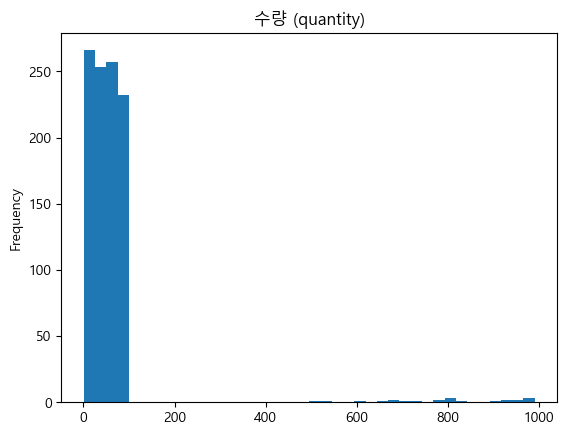

In [18]:
df["quantity"].plot.hist(bins=40, title="수량 (quantity)") 
plt.show()

In [19]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1

print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


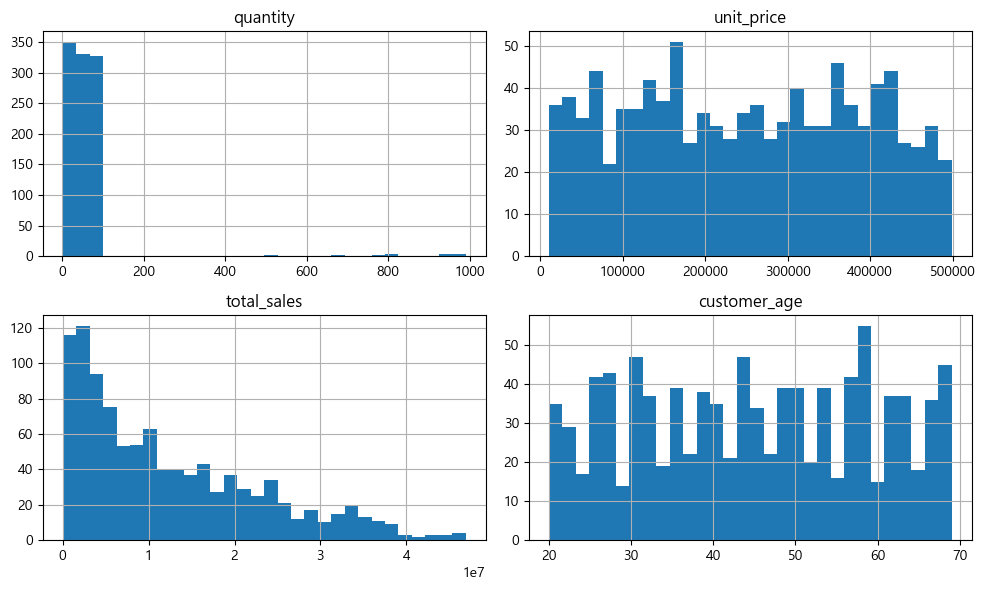

In [20]:
cols = ["quantity", "unit_price", "total_sales", "customer_age"]

df[cols].hist(
    bins=30,
    figsize=(10, 6),
)

plt.tight_layout()
plt.show()

In [21]:
dropped = df.dropna(subset=["customer_age"]) 
print(len(df), "->", len(dropped))        # 개수만 나옴. 실제 드롭은 안 하는 코드.

1030 -> 979


In [22]:
age_mean = df["customer_age"].fillna(
    df["customer_age"].mean()
)

print("평균  :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

평균  : 44.858
중앙값: 44.858
최빈값: 44.858


In [23]:
# 결정: 세칸의빈칸은그대로둔다
print(df["customer_age"].count(), "/", len(df))

979 / 1030


In [24]:
before = len(df) 
df = df.drop_duplicates()   # 중복만 줄여서 가자. 드롭시키고 df에 새로 저장.
print(before, "->", len(df)) 

1030 -> 1004


In [25]:
# 통계 규칙: 26쪽에서 구한 상한 150을 벗어나는 값
by_iqr = df["quantity"] > Q3 + 1.5 * IQR

# 업무 규칙: 한 주문은 100개를 넘지 않는다
by_rule = df["quantity"] > 100

print(
    "IQR 규칙:",
    by_iqr.sum(),
    "업무 규칙:",
    by_rule.sum(),
    "둘이 같은 줄인가:",
    (by_iqr == by_rule).all(),
)

IQR 규칙: 22 업무 규칙: 22 둘이 같은 줄인가: True


In [26]:
bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()

print("22건 중 금액이 안 맞는 줄:", (diff[bad] > 1).sum())

ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)

22건 중 금액이 안 맞는 줄: 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

In [27]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)

calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()

print("고친줄:", bad.sum(), " 수량최대:", df["quantity"].max(), " 총액안맞는줄:", (diff > 1).sum())

고친줄: 22  수량최대: 99  총액안맞는줄: 0


In [28]:
df["date_error"] = df["delivery_date"] < df["shipping_date"] 
df["date_error"].value_counts()

date_error
False    857
True     147
Name: count, dtype: int64

In [29]:
df.to_csv("sales_clean.csv", index=False) 
df.shape

(1004, 15)

### ⑤ 배송 기간(도착일 − 배송일)은 보통 며칠인가?

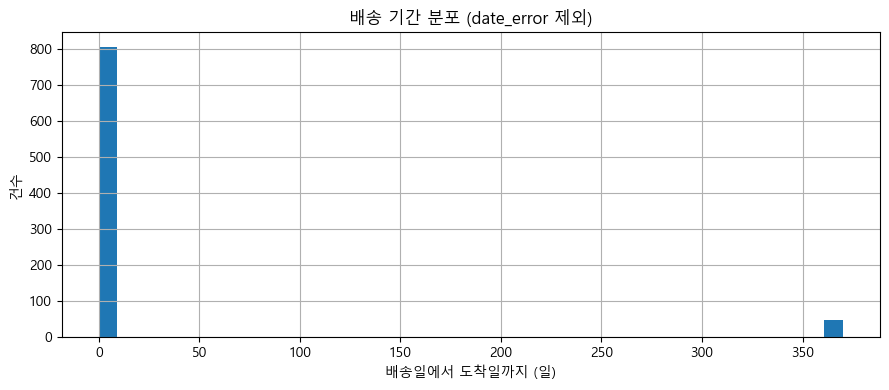

날짜 순서가 맞고 기간이 있는 건: 852건
전체 평균: 22.05일, 중앙값: 2일
300일 초과: 47건, 범위: 364~370일
300일 초과를 분석에서 제외한 평균: 1.93일, 중앙값: 2일


In [30]:
days = (df.loc[~df["date_error"], "delivery_date"]
        - df.loc[~df["date_error"], "shipping_date"]).dt.days.dropna()

ax = days.hist(bins=40, figsize=(9, 4))
ax.set_title("배송 기간 분포 (date_error 제외)")
ax.set_xlabel("배송일에서 도착일까지 (일)")
ax.set_ylabel("건수")
plt.tight_layout()
plt.show()

long_days = days[days > 300]
usual_days = days[days <= 300]
print(f"날짜 순서가 맞고 기간이 있는 건: {len(days)}건")
print(f"전체 평균: {days.mean():.2f}일, 중앙값: {days.median():.0f}일")
print(f"300일 초과: {len(long_days)}건, 범위: {long_days.min():.0f}~{long_days.max():.0f}일")
print(f"300일 초과를 분석에서 제외한 평균: {usual_days.mean():.2f}일, 중앙값: {usual_days.median():.0f}일")

전체 852건의 평균은 **22.05일**, 중앙값은 **2일**로, 평균이 364~370일인 47건에 크게 끌려갑니다.  
이 47건은 원인 확인이 필요한 값이므로 보통 기간 계산에서만 제외해 평균 **1.93일**, 중앙값 **2일**로 보고 원본과 저장 CSV는 수정하지 않습니다.

### ⑥ 만족도가 낮을수록 반품이 많은가?

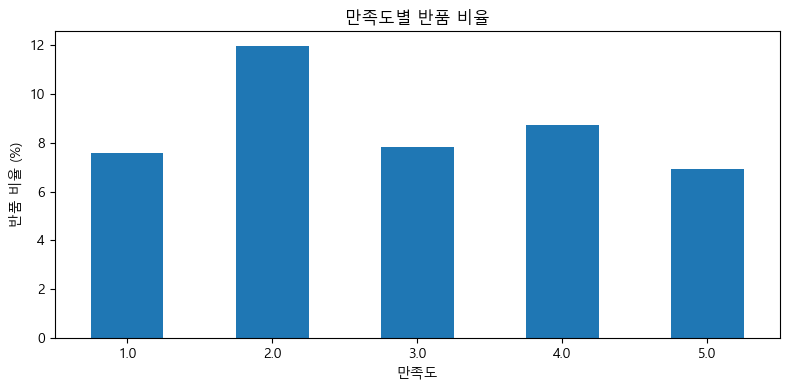

satisfaction
1.0     7.59
2.0    11.96
3.0     7.81
4.0     8.72
5.0     6.93


In [31]:
return_pct = (df.assign(is_return=df["status"].eq("반품"))
              .groupby("satisfaction")["is_return"].mean() * 100)
ax = return_pct.plot.bar(figsize=(8, 4), rot=0)
ax.set_title("만족도별 반품 비율")
ax.set_xlabel("만족도")
ax.set_ylabel("반품 비율 (%)")
plt.tight_layout()
plt.show()
print(return_pct.round(2).to_string())

**아닙니다.** 만족도 1~5점의 반품률은 각각 **7.59%, 11.96%, 7.81%, 8.72%, 6.93%**로 일관된 증가 추세가 없습니다.  
가장 높은 비율은 2점의 **11.96%**이며, 만족도 결측 30건은 이 비교에서 제외했습니다.

### ⑦ 카테고리 매출 1위의 이유는 무엇인가?

In [32]:
category_summary = (df.groupby("category")
                    .agg(건수=("total_sales", "size"),
                         매출합계_원=("total_sales", "sum"),
                         평균단가_원=("unit_price", "mean"),
                         평균수량_개=("quantity", "mean"))
                    .sort_values("매출합계_원", ascending=False))
category_summary.round(2)

,건수,매출합계_원,평균단가_원,평균수량_개
category,,,,
가구,213,2.843337e+09,257322.91,51.04
식품,210,2.513274e+09,255232.93,47.31
전자제품,207,2.471628e+09,249651.61,47.96
도서,204,2.453240e+09,238500.64,49.50
의류,170,2.181904e+09,249447.16,51.61


매출 1위는 **가구 28.43억 원**, 2위는 **식품 25.13억 원**입니다.  
가구와 식품의 건수는 **213 대 210**, 평균 단가는 **257,323원 대 255,233원**, 평균 수량은 **51.04개 대 47.31개**로, 세 지표 중 평균 수량 차이가 가장 큽니다.

In [33]:
#------------------

df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)

# bad관련 처리를 안 했기 때문에 skew가 강의자료에 비해 높게 나왔다. (17page)

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


In [34]:
# 고치기 전 파일을 다시 읽어 비교
raw = pd.read_csv("sales_data.csv")

print(
    "수량-총액 상관계수 고치기 전:",
    round(raw["quantity"].corr(raw["total_sales"]), 2),
    "고친 뒤:",
    round(df["quantity"].corr(df["total_sales"]), 2),
)

수량-총액 상관계수 고치기 전: 0.21 고친 뒤: 0.67


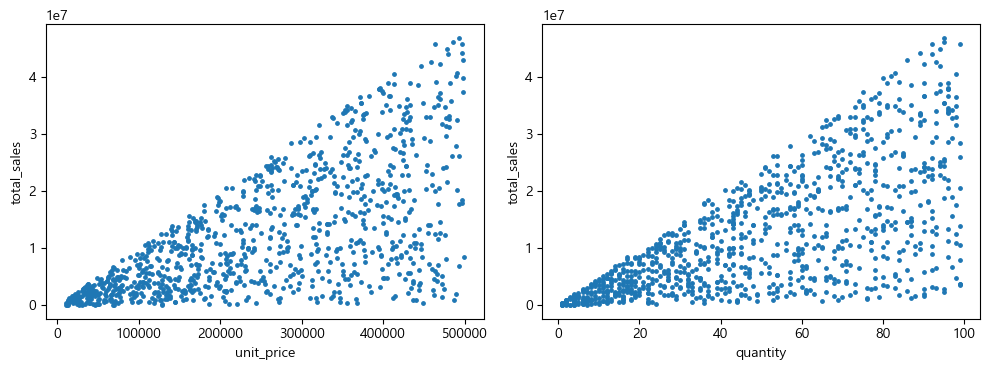

In [35]:
fig, ax = plt.subplots(
    1,
    2,
    figsize=(10, 3.8),
)

df.plot.scatter(
    x="unit_price",
    y="total_sales",
    s=6,
    ax=ax[0],
)

df.plot.scatter(
    x="quantity",
    y="total_sales",
    s=6,
    ax=ax[1],
)

plt.tight_layout()
plt.show()

In [36]:
num = ["quantity", "unit_price", "total_sales", "customer_age", "satisfaction"] 
df[num].corr().round(2)

,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


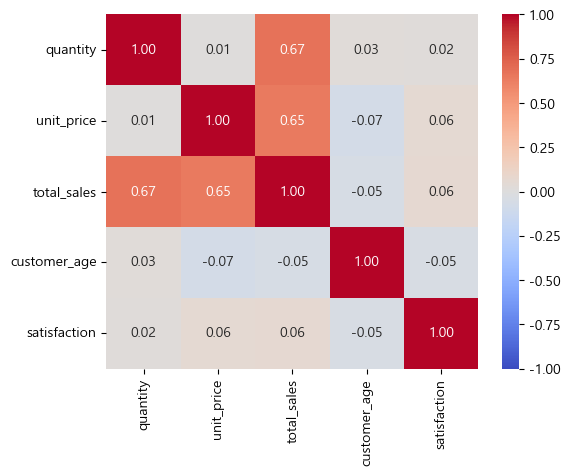

In [37]:
import seaborn as sns

plt.figure(figsize=(6, 4.6))

sns.heatmap(
    df[num].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.show()

In [38]:
by_cat = df.groupby("category")["total_sales"].sum() 
(by_cat / 1e8).round(1)            # 억 원단위

category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: total_sales, dtype: float64

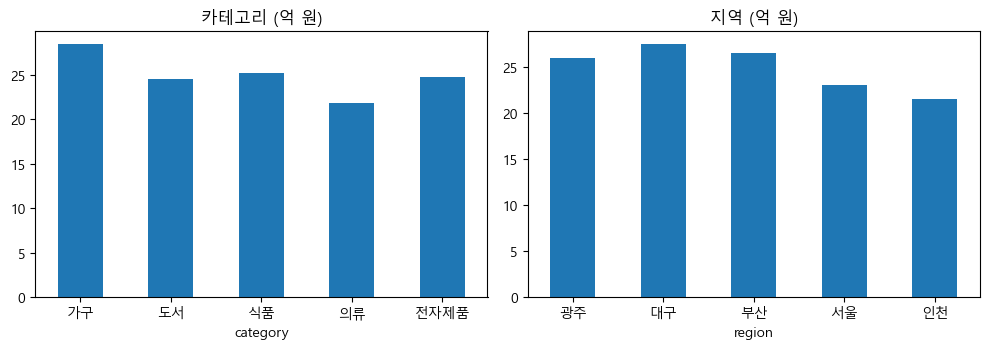

In [39]:
by_reg = df.groupby("region")["total_sales"].sum()

fig, ax = plt.subplots(
    1,
    2,
    figsize=(10, 3.6),
)

(by_cat / 1e8).plot.bar(
    ax=ax[0],
    title="카테고리 (억 원)",
    rot=0,
)

(by_reg / 1e8).plot.bar(
    ax=ax[1],
    title="지역 (억 원)",
    rot=0,
)

plt.tight_layout()
plt.show()

In [40]:
pv = df.pivot_table(
    index="region",
    columns="category",
    values="total_sales",
    aggfunc="sum",
)

(pv / 1e8).round(1)

category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


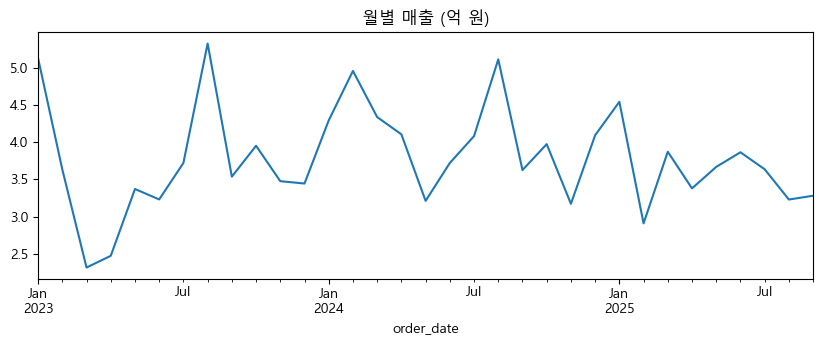

(Period('2023-08', 'M'), np.float64(5.3))

In [41]:
month = df["order_date"].dt.to_period("M")

monthly = (
    df.groupby(month)["total_sales"].sum()
    / 1e8
)

monthly.plot(
    figsize=(10, 3.2),
    title="월별 매출 (억 원)",
)

plt.show()

monthly.idxmax(), round(monthly.max(), 1)